In [145]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.ensemble import RandomForestClassifier
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression

#Load data
teams = pd.read_csv('data/clean_teams.csv')
s11_players_teams = pd.read_csv('data/season_11/players_teams.csv')
s11_players_teams = s11_players_teams.drop(['lgID'], axis=1)
s11_teams = pd.read_csv('data/season_11/teams.csv')
s11_teams = s11_teams.drop(['name','franchID','arena','lgID'], axis=1)
s11_coaches = pd.read_csv('data/season_11/coaches.csv')
teams

,Unnamed: 0,year,tmID,confID,playoff,firstRound,semis,finals,o_fgm,o_fga,...,won,lost,GP,homeW,homeL,awayW,awayL,confW,confL,min
0,0,9,ATL,EA,N,NaN,NaN,NaN,895,2258,...,4,30,34,1,16,3,14,2,18,6825
1,1,10,ATL,EA,Y,L,NaN,NaN,1089,2428,...,18,16,34,12,5,6,11,10,12,6950
2,2,1,CHA,EA,N,NaN,NaN,NaN,812,1903,...,8,24,32,5,11,3,13,5,16,6475
3,3,2,CHA,EA,Y,W,W,L,746,1780,...,18,14,32,11,5,7,9,15,6,6500
4,4,3,CHA,EA,Y,L,NaN,NaN,770,1790,...,18,14,32,11,5,7,9,12,9,6450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,EA,N,NaN,NaN,NaN,847,1968,...,16,18,34,10,7,6,11,9,11,6900
138,138,7,WAS,EA,Y,L,NaN,NaN,1016,2199,...,18,16,34,13,4,5,12,12,8,6850
139,139,8,WAS,EA,N,NaN,NaN,NaN,877,2170,...,16,18,34,8,9,8,9,8,12,6900
140,140,9,WAS,EA,N,NaN,NaN,NaN,885,2131,...,10,24,34,6,11,4,13,6,14,6825


In [146]:
# Binary encoding for 'playoff' column
teams['playoff'] = (teams['playoff'] == 'Y').astype(int)

# Encoding for 'firstRound' column
teams['firstRound'] = teams['firstRound'].fillna(0)
teams['firstRound'] = teams['firstRound'].replace('W',1)
teams['firstRound'] = teams['firstRound'].replace('L',1)

# Encoding for 'semis' and 'finals' columns
teams['semis'] = teams['semis'].fillna(0)
teams['semis'] = teams['semis'].replace('W',1)
teams['semis'] = teams['semis'].replace('L',1)

teams['finals'] = teams['finals'].fillna(0)
teams['finals'] = teams['finals'].replace('W',2) # 2 for finals (1 semis)
teams['finals'] = teams['finals'].replace('L',1)

# Combining playoff-related columns into 'playoff_result' and dropping individual columns
teams['playoff_result'] = teams['firstRound'] + teams['semis'] + teams['finals']
teams = teams.drop(['firstRound','semis','finals'], axis=1)

# Binary encoding for 'east' and 'west' based on 'confID'
teams['east'] = (teams['confID'] == 'EA').astype(int)
teams['west'] = (teams['confID'] == 'WE').astype(int)

# Doing the same for season 11 teams
s11_teams['east'] = (s11_teams['confID'] == 'EA').astype(int)
s11_teams['west'] = (s11_teams['confID'] == 'WE').astype(int)
s11_teams = s11_teams.drop(['confID'], axis=1)
print(s11_teams)

teams.drop('confID', axis=1, inplace=True)

teams

    year tmID  east  west
0     11  ATL     1     0
1     11  CHI     1     0
2     11  CON     1     0
3     11  IND     1     0
4     11  LAS     0     1
5     11  MIN     0     1
6     11  NYL     1     0
7     11  PHO     0     1
8     11  SAS     0     1
9     11  SEA     0     1
10    11  TUL     0     1
11    11  WAS     1     0


,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,homeW,homeL,awayW,awayL,confW,confL,min,playoff_result,east,west
0,0,9,ATL,0,895,2258,542,725,202,598,...,1,16,3,14,2,18,6825,0,1,0
1,1,10,ATL,1,1089,2428,569,755,114,374,...,12,5,6,11,10,12,6950,1,1,0
2,2,1,CHA,0,812,1903,431,577,131,386,...,5,11,3,13,5,16,6475,0,1,0
3,3,2,CHA,1,746,1780,410,528,153,428,...,11,5,7,9,15,6,6500,3,1,0
4,4,3,CHA,1,770,1790,490,663,211,527,...,11,5,7,9,12,9,6450,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,847,1968,388,546,181,510,...,10,7,6,11,9,11,6900,0,1,0
138,138,7,WAS,1,1016,2199,528,715,187,522,...,13,4,5,12,12,8,6850,1,1,0
139,139,8,WAS,0,877,2170,668,839,163,528,...,8,9,8,9,8,12,6900,0,1,0
140,140,9,WAS,0,885,2131,435,659,163,460,...,6,11,4,13,6,14,6825,0,1,0


In [147]:
teams['win_ratio'] = teams['won'] / teams['GP']
teams['win_ratio'] = teams['win_ratio'].apply(lambda x: round(x, 2))

teams.drop(['won','lost', 'GP'], axis=1, inplace=True)

teams

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,homeL,awayW,awayL,confW,confL,min,playoff_result,east,west,win_ratio
0,0,9,ATL,0,895,2258,542,725,202,598,...,16,3,14,2,18,6825,0,1,0,0.12
1,1,10,ATL,1,1089,2428,569,755,114,374,...,5,6,11,10,12,6950,1,1,0,0.53
2,2,1,CHA,0,812,1903,431,577,131,386,...,11,3,13,5,16,6475,0,1,0,0.25
3,3,2,CHA,1,746,1780,410,528,153,428,...,5,7,9,15,6,6500,3,1,0,0.56
4,4,3,CHA,1,770,1790,490,663,211,527,...,5,7,9,12,9,6450,1,1,0,0.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,847,1968,388,546,181,510,...,7,6,11,9,11,6900,0,1,0,0.47
138,138,7,WAS,1,1016,2199,528,715,187,522,...,4,5,12,12,8,6850,1,1,0,0.53
139,139,8,WAS,0,877,2170,668,839,163,528,...,9,8,9,8,12,6900,0,1,0,0.47
140,140,9,WAS,0,885,2131,435,659,163,460,...,11,4,13,6,14,6825,0,1,0,0.29


In [148]:
#Possessions = Team Possessions = 0.5 * ((Team FGA + 0.4 * Team FTA - 1.07 * (Team OREB / (Team OREB + Opponent DREB)) * (Team FGA - Team FG) + Team TO) + (Opponent FGA + 0.4 * Opponent FTA - 1.07 * (Opponent OREB / (Opponent OREB + Team DREB)) * (Opponent FGA - Opponent FG) + Opponent TO))
teams['possesions'] = 0.5 * (teams['o_fga'] + 0.4 * teams['o_fta'] - 1.07 * (teams['o_oreb'] / (teams['o_oreb'] + teams['d_dreb'])) * (teams['o_fga'] - teams['o_fgm']) + teams['o_to']+
                             teams['d_fga'] + 0.4 * teams['d_fta'] - 1.07 * (teams['d_oreb'] / (teams['d_oreb'] + teams['o_dreb'])) * (teams['d_fga'] - teams['d_fgm']) + teams['d_to'])

In [149]:
#OFF EFF = 100 x (Points / Possessions)
teams['off_rtg'] = 100 * (teams['o_pts'] / teams['possesions'])
teams['off_rtg'] = teams['off_rtg'].apply(lambda x: round(x, 1))

#DEF EFF = 100 x (Opponent Points / Opponent Possessions)
teams['def_rtg'] = 100 * (teams['d_pts'] / teams['possesions'])
teams['def_rtg'] = teams['def_rtg'].apply(lambda x: round(x, 1))

# NET EFF = OFF EFF - DEF EFF
teams['net_rtg'] = teams['off_rtg'] - teams['def_rtg']
teams['net_rtg'] = teams['net_rtg'].apply(lambda x: round(x, 1))

teams.drop(['possesions', 'off_rtg', 'def_rtg'], axis=1, inplace=True)
teams.head()

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,awayW,awayL,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg
0,0,9,ATL,0,895,2258,542,725,202,598,...,3,14,2,18,6825,0,1,0,0.12,-12.7
1,1,10,ATL,1,1089,2428,569,755,114,374,...,6,11,10,12,6950,1,1,0,0.53,2.3
2,2,1,CHA,0,812,1903,431,577,131,386,...,3,13,5,16,6475,0,1,0,0.25,-10.7
3,3,2,CHA,1,746,1780,410,528,153,428,...,7,9,15,6,6500,3,1,0,0.56,2.2
4,4,3,CHA,1,770,1790,490,663,211,527,...,7,9,12,9,6450,1,1,0,0.56,5.1


In [150]:
# As we aggregate several columns into one, we no longer need the intermediate columns
# Dropping offensive statistics columns
teams.drop(["o_fgm", "o_fga", "o_ftm", "o_fta", "o_3pm", "o_3pa", "o_oreb", "o_dreb", "o_reb", "o_asts", "o_pf", "o_stl", "o_to", "o_blk", "o_pts"], axis=1, inplace=True)

# Dropping defensive statistics, home/away wins and losses columns
teams.drop(["d_fgm", "d_fga", "d_ftm", "d_fta", "d_3pm", "d_3pa", "d_oreb", "d_dreb", "d_reb", "d_asts", "d_pf", "d_stl", "d_to", "d_blk", "d_pts", "homeW", "homeL", "awayW", "awayL"], axis=1, inplace=True)
teams.head()

,Unnamed: 0,year,tmID,playoff,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg
0,0,9,ATL,0,2,18,6825,0,1,0,0.12,-12.7
1,1,10,ATL,1,10,12,6950,1,1,0,0.53,2.3
2,2,1,CHA,0,5,16,6475,0,1,0,0.25,-10.7
3,3,2,CHA,1,15,6,6500,3,1,0,0.56,2.2
4,4,3,CHA,1,12,9,6450,1,1,0,0.56,5.1


In [151]:
players_teams_data = pd.read_csv("data/players_teams.csv")


In [152]:
# delete players who haven't played
players_teams_data = players_teams_data[players_teams_data['minutes'] != 0]

#players_teams_data['UE'] = (players_teams_data['fgAttempted'] + 0.44 * players_teams_data['ftAttempted'] + players_teams_data['turnovers']) * 100 / players_teams_data['minutes']
players_teams_data['PPG'] = players_teams_data['points'] / players_teams_data['GP']
players_teams_data['SPG'] = players_teams_data['steals'] / players_teams_data['GP']
players_teams_data['TOVPG'] = players_teams_data['turnovers'] / players_teams_data['GP']


In [153]:
players_teams_data['PPG'] = players_teams_data['PPG'].apply(lambda x: round(x, 1))

players_teams_data['SPG'] = players_teams_data['SPG'].apply(lambda x: round(x, 1))

players_teams_data['TOVPG'] = players_teams_data['TOVPG'].apply(lambda x: round(x, 1))

players_teams_data[['playerID', 'year', 'PPG', 'SPG', 'TOVPG']]

,playerID,year,PPG,SPG,TOVPG
0,abrossv01w,2,13.2,1.6,3.3
1,abrossv01w,3,11.6,1.6,3.4
2,abrossv01w,4,10.6,1.5,3.0
3,abrossv01w,5,6.6,1.4,2.0
4,abrossv01w,6,9.8,1.5,2.6
...,...,...,...,...,...
1871,zakalok01w,3,1.2,0.0,0.8
1872,zarafr01w,6,2.6,0.5,1.2
1873,zellosh01w,10,11.9,0.8,2.3
1874,zirkozu01w,4,1.8,0.0,0.3


In [154]:
players_teams_data.drop(["points", "steals", 'turnovers', "GP"], axis=1, inplace=True)
players_teams_data

,playerID,year,stint,tmID,lgID,GS,minutes,oRebounds,dRebounds,rebounds,...,PostfgAttempted,PostfgMade,PostftAttempted,PostftMade,PostthreeAttempted,PostthreeMade,PostDQ,PPG,SPG,TOVPG
0,abrossv01w,2,0,MIN,WNBA,23,846,43,131,174,...,0,0,0,0,0,0,0,13.2,1.6,3.3
1,abrossv01w,3,0,MIN,WNBA,27,805,45,101,146,...,0,0,0,0,0,0,0,11.6,1.6,3.4
2,abrossv01w,4,0,MIN,WNBA,25,792,44,97,141,...,22,6,8,8,7,3,0,10.6,1.5,3.0
3,abrossv01w,5,0,MIN,WNBA,11,462,17,57,74,...,23,8,4,2,8,2,0,6.6,1.4,2.0
4,abrossv01w,6,0,MIN,WNBA,31,777,29,78,107,...,0,0,0,0,0,0,0,9.8,1.5,2.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1871,zakalok01w,3,2,PHO,WNBA,0,37,0,3,3,...,0,0,0,0,0,0,0,1.2,0.0,0.8
1872,zarafr01w,6,0,SEA,WNBA,4,413,11,28,39,...,6,4,2,2,1,1,0,2.6,0.5,1.2
1873,zellosh01w,10,0,DET,WNBA,4,802,25,81,106,...,68,24,27,23,17,7,0,11.9,0.8,2.3
1874,zirkozu01w,4,0,WAS,WNBA,0,30,0,2,2,...,0,0,0,0,0,0,0,1.8,0.0,0.3


In [155]:
average_ppg = players_teams_data.groupby(['year', 'tmID'])['PPG'].mean().reset_index()
average_ppg['PPG'] = average_ppg['PPG'].apply(lambda x: round(x, 2))
average_ppg

average_spg = players_teams_data.groupby(['year', 'tmID'])['SPG'].mean().reset_index()
average_spg['SPG'] = average_spg['SPG'].apply(lambda x: round(x, 2))
average_spg

average_tovpg= players_teams_data.groupby(['year', 'tmID'])['TOVPG'].mean().reset_index()
average_tovpg['TOVPG'] = average_tovpg['TOVPG'].apply(lambda x: round(x, 2))
average_tovpg

,year,tmID,TOVPG
0,1,CHA,1.42
1,1,CLE,1.53
2,1,DET,1.40
3,1,HOU,1.22
4,1,IND,1.30
...,...,...,...
137,10,PHO,1.43
138,10,SAC,1.38
139,10,SAS,1.58
140,10,SEA,1.49


In [156]:
teams = pd.merge(teams, average_ppg, how='left', left_on=['year', 'tmID'], right_on=['year', 'tmID'], suffixes=('', '_avg_ppg'))
teams = pd.merge(teams, average_spg, how='left', left_on=['year', 'tmID'], right_on=['year', 'tmID'], suffixes=('', '_avg_ppg'))
teams = pd.merge(teams, average_tovpg, how='left', left_on=['year', 'tmID'], right_on=['year', 'tmID'], suffixes=('', '_avg_tovpg'))
teams

,Unnamed: 0,year,tmID,playoff,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg,PPG,SPG,TOVPG
0,0,9,ATL,0,2,18,6825,0,1,0,0.12,-12.7,6.45,0.84,1.41
1,1,10,ATL,1,10,12,6950,1,1,0,0.53,2.3,7.34,0.88,1.52
2,2,1,CHA,0,5,16,6475,0,1,0,0.25,-10.7,6.45,0.65,1.42
3,3,2,CHA,1,15,6,6500,3,1,0,0.56,2.2,5.75,0.59,1.42
4,4,3,CHA,1,12,9,6450,1,1,0,0.56,5.1,5.69,0.67,0.96
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,9,11,6900,0,1,0,0.47,-1.9,5.62,0.72,1.10
138,138,7,WAS,1,12,8,6850,1,1,0,0.53,3.4,7.67,0.87,1.44
139,139,8,WAS,0,8,12,6900,0,1,0,0.47,-2.1,6.31,0.79,1.27
140,140,9,WAS,0,6,14,6825,0,1,0,0.29,-9.0,5.53,0.56,1.52


In [157]:
# Joining season 11 teams info
teams = teams.append(s11_teams)
teams

C:\Users\Utilizador\AppData\Local\Temp\ipykernel_11092\2945613847.py:2: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  teams = teams.append(s11_teams)


,Unnamed: 0,year,tmID,playoff,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg,PPG,SPG,TOVPG
0,0.0,9,ATL,0.0,2.0,18.0,6825.0,0.0,1,0,0.12,-12.7,6.45,0.84,1.41
1,1.0,10,ATL,1.0,10.0,12.0,6950.0,1.0,1,0,0.53,2.3,7.34,0.88,1.52
2,2.0,1,CHA,0.0,5.0,16.0,6475.0,0.0,1,0,0.25,-10.7,6.45,0.65,1.42
3,3.0,2,CHA,1.0,15.0,6.0,6500.0,3.0,1,0,0.56,2.2,5.75,0.59,1.42
4,4.0,3,CHA,1.0,12.0,9.0,6450.0,1.0,1,0,0.56,5.1,5.69,0.67,0.96
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7,NaN,11,PHO,NaN,NaN,NaN,NaN,NaN,0,1,NaN,NaN,NaN,NaN,NaN
8,NaN,11,SAS,NaN,NaN,NaN,NaN,NaN,0,1,NaN,NaN,NaN,NaN,NaN
9,NaN,11,SEA,NaN,NaN,NaN,NaN,NaN,0,1,NaN,NaN,NaN,NaN,NaN
10,NaN,11,TUL,NaN,NaN,NaN,NaN,NaN,0,1,NaN,NaN,NaN,NaN,NaN


In [158]:
teams_previous_year = teams.copy()

# Creating a new column with the previous year
teams_previous_year['year_previous'] = teams_previous_year['year'] + 1

# Selecting relevant columns for obtaining previous year data
columns_to_include = ['playoff_result', 'win_ratio', 'net_rtg', 'PPG', 'SPG', 'TOVPG']
teams_previous_year = teams_previous_year[['year_previous', 'tmID'] + columns_to_include]

teams_previous_year.columns = ['year_previous', 'tmID'] + [f'{col}_previous' for col in columns_to_include]

# Merging tables to get previous year data based on 'tmID' and 'next_year'
teams = pd.merge(teams, teams_previous_year, how='left', left_on=['year', 'tmID'], right_on=['year_previous', 'tmID'])

# Dropping the redundant column 'year_previous'
teams = teams.drop(['year_previous'], axis=1)


<AxesSubplot:>

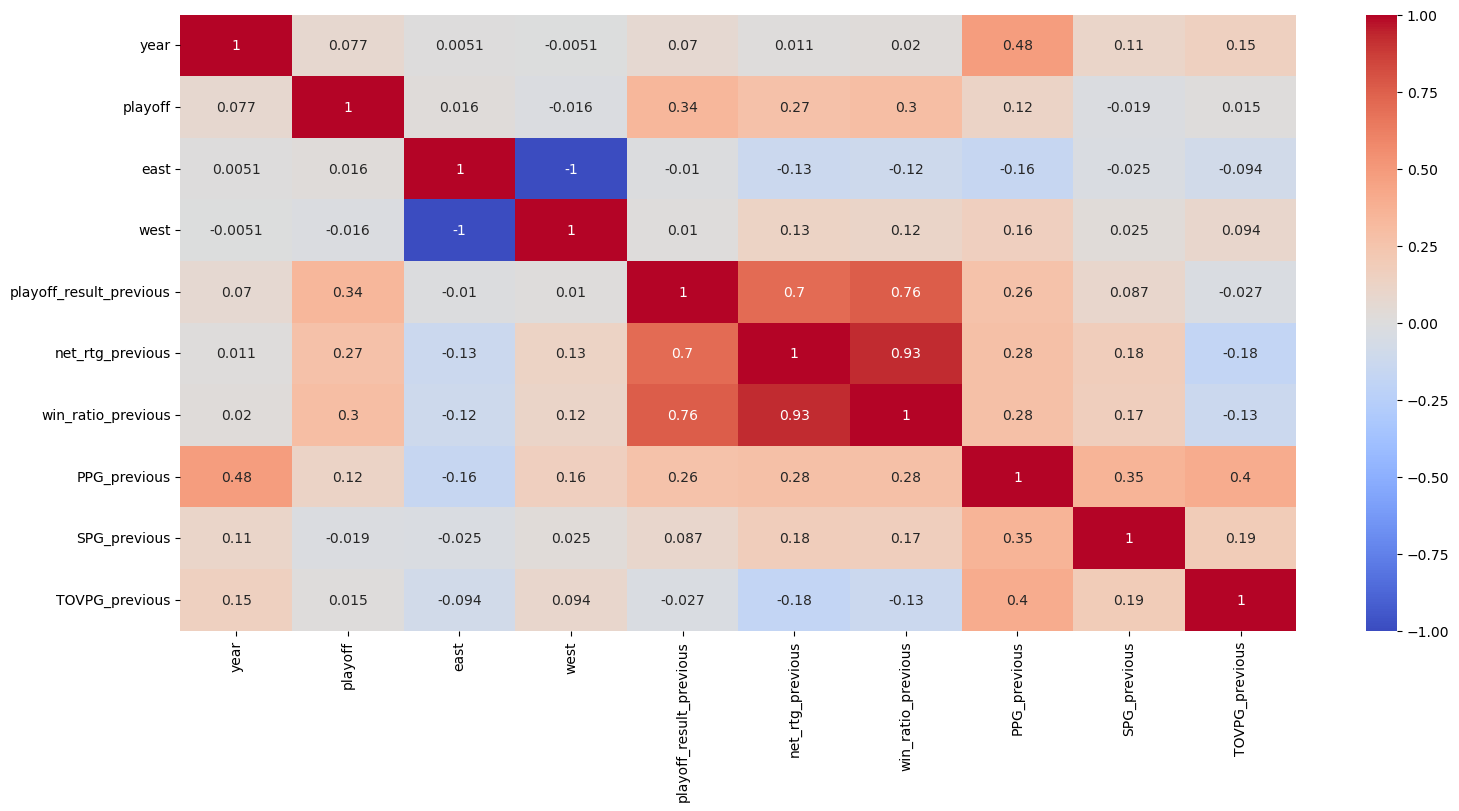

In [159]:
# Selecting specific columns of interest for correlation analysis
teams = teams[['year', 'tmID','playoff','east','west','playoff_result_previous','net_rtg_previous','win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']]

# Correlation matrix visualization
plt.figure(figsize=(18,8))
correlation = teams.corr()
sb.heatmap(correlation,annot=True,cmap='coolwarm')

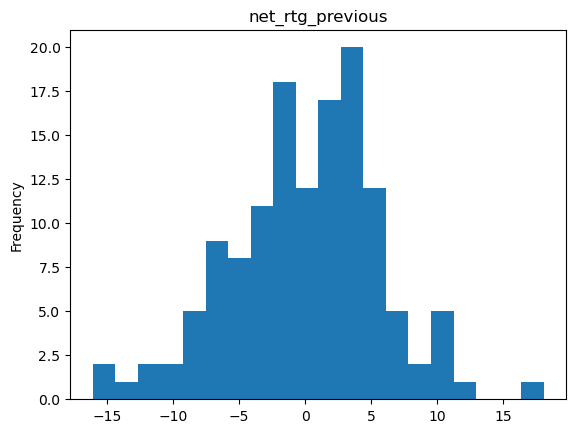

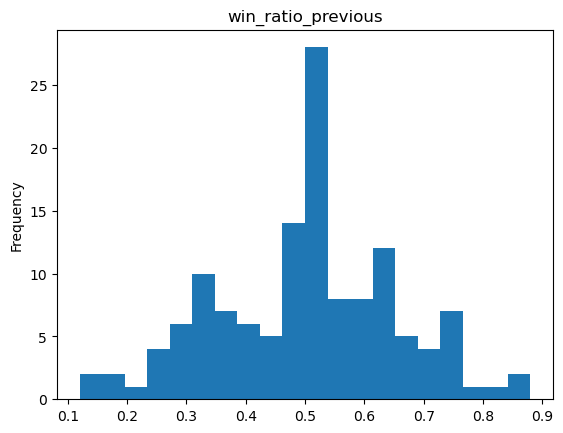

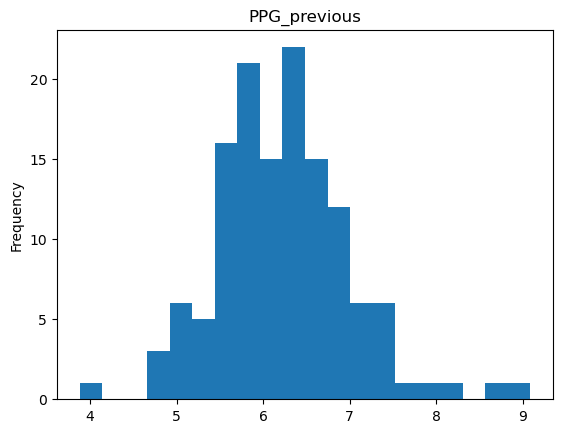

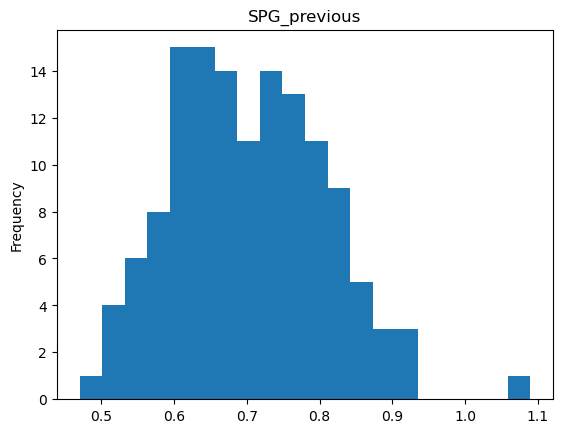

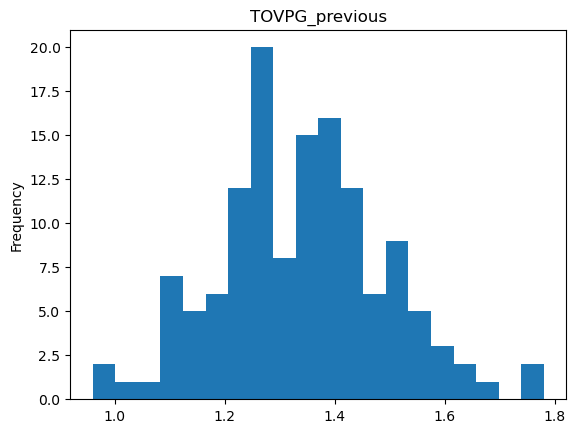

In [160]:
columns = ['net_rtg_previous', 'win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']

for col in columns:
    teams[col].plot(kind='hist', bins=20, title=col)
    plt.show()

In [161]:
for col in columns:
    skewness = teams[col].skew()
    print(f"Assimetry of {col}: {skewness}")

Assimetry of net_rtg_previous: -0.1572236538530343
Assimetry of win_ratio_previous: -0.0647189144816795
Assimetry of PPG_previous: 0.4864311996398967
Assimetry of SPG_previous: 0.45436923342709074
Assimetry of TOVPG_previous: 0.20480986977784166


In [162]:
"""
for col in ['net_rtg_previous', 'win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']:
    if(col == 'net_rtg_previous' and 'win_ratio_previous'):
        teams[col].fillna(teams[col].mean(), inplace=True)
    else:
        teams[col].fillna(teams[col].median(), inplace=True)
"""
# From a business understanding point of view it doesn't make sense to fill the missing values with the median or mean, because it could alter negatively the results.

"\nfor col in ['net_rtg_previous', 'win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']:\n    if(col == 'net_rtg_previous' and 'win_ratio_previous'):\n        teams[col].fillna(teams[col].mean(), inplace=True)\n    else:\n        teams[col].fillna(teams[col].median(), inplace=True)\n"

In [163]:
s11_team_ids = set(s11_teams['tmID'].unique())
team_ids = set(teams['tmID'].unique())

missing_teams = s11_team_ids.difference(team_ids)

print(missing_teams)
print(teams['tmID'].unique())

set()
['ATL' 'CHA' 'CHI' 'CLE' 'CON' 'DET' 'HOU' 'IND' 'LAS' 'MIA' 'MIN' 'NYL'
 'ORL' 'PHO' 'POR' 'SAC' 'SAS' 'SEA' 'UTA' 'WAS' 'TUL']


In [164]:
# Select relevant columns to create a new dataframe
new_df = teams[['year','tmID','playoff','east','west', 'playoff_result_previous','net_rtg_previous','win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']]
columns_with_missing_values = new_df.columns[new_df.isna().any()].tolist()

# Fill the missing values with 0 except for the target column
columns_with_missing_values.remove('playoff')
new_df.loc[:, columns_with_missing_values] = new_df[columns_with_missing_values].fillna(0)
print(new_df['year'].unique())

[ 9 10  1  2  3  4  5  6  7  8 11]


In [165]:
# encoding categorical data
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
new_df['tmID'] = encoder.fit_transform(new_df['tmID'])

## Testing models using Sliding Window

In [166]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC   
from sklearn.decomposition import PCA

def sliding_window_split(new_df, window_size, target_column,n_components=0):
    splits = []
    test_years = []
    min_year = new_df['year'].min()
    max_year = new_df['year'].max()-1
    print("Min Year:", min_year)
    print("Max Year:", max_year)

    for start_year in range(min_year, max_year - window_size + 1):
        end_year = start_year + window_size - 1
        test_year = end_year + 1
        test_years.append(test_year)
       
        # Training data
        train_mask = (new_df['year'] >= start_year) & (new_df['year'] <= end_year)
        X_train = new_df[train_mask].drop([target_column], axis=1)
        y_train = new_df[train_mask][target_column]
        print("Training Years:", start_year ," to ", end_year)  

        # Test data
        test_mask = new_df['year'] == end_year + 1
        X_test = new_df[test_mask].drop([target_column], axis=1)
        y_test = new_df[test_mask][target_column]
        print("Testing Year:", end_year +1)  
        print("")

        # Removing 'year' column
        X_train = X_train.drop(['year'], axis=1)
        X_test = X_test.drop(['year'], axis=1)

        # PCA
        if n_components > 0:
            pca = PCA(n_components=n_components)
            pca.fit(X_train)
            X_train = pca.transform(X_train)
            X_test = pca.transform(X_test)

        splits.append((X_train, X_test, y_train, y_test))

    return splits,test_years

window_size = 5
target_column = 'playoff'

splits,test_years = sliding_window_split(new_df, window_size, target_column)


Min Year: 1
Max Year: 10
Training Years: 1  to  5
Testing Year: 6

Training Years: 2  to  6
Testing Year: 7

Training Years: 3  to  7
Testing Year: 8

Training Years: 4  to  8
Testing Year: 9

Training Years: 5  to  9
Testing Year: 10



LogisticRegression [0.6153846153846154, 0.7857142857142857, 0.5384615384615384, 0.7857142857142857, 0.5384615384615384]
Mean:  0.6527472527472526
Standard Deviation: 0.11214176685106743
RandomForestClassifier [0.6153846153846154, 0.7142857142857143, 0.6153846153846154, 0.7142857142857143, 0.46153846153846156]
Mean:  0.6241758241758243
Standard Deviation: 0.09256896566440741
DecisionTreeClassifier [0.46153846153846156, 0.6428571428571429, 0.46153846153846156, 0.7142857142857143, 0.6153846153846154]
Mean:  0.5791208791208792
Standard Deviation: 0.1012898340378278
GradientBoostingClassifier [0.5384615384615384, 0.7142857142857143, 0.5384615384615384, 0.7142857142857143, 0.46153846153846156]
Mean:  0.5934065934065934
Standard Deviation: 0.1026164178455275
SVC [0.7692307692307693, 0.7142857142857143, 0.6153846153846154, 0.5714285714285714, 0.5384615384615384]
Mean:  0.6417582417582418
Standard Deviation: 0.08697300631828302


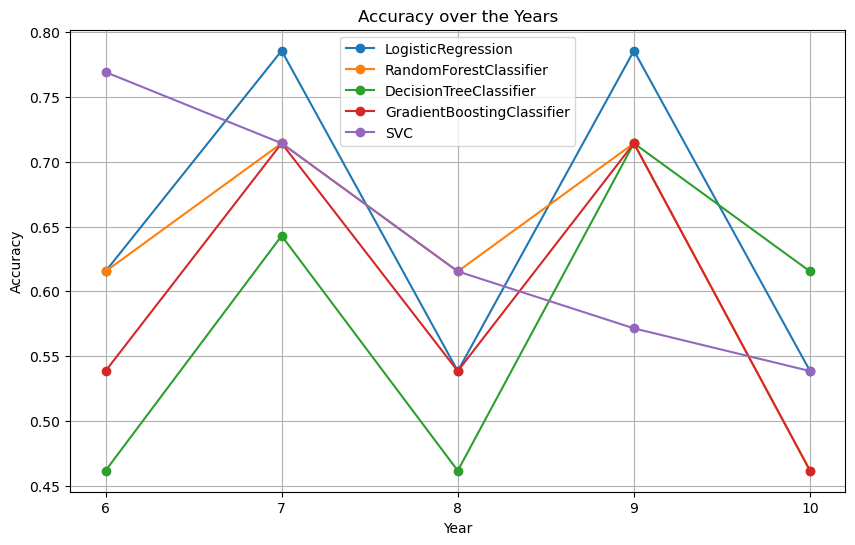

In [167]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.metrics import f1_score

models = [
    LogisticRegression(random_state=42),
    RandomForestClassifier(n_estimators=200, random_state=42),
    DecisionTreeClassifier(random_state=42),
    GradientBoostingClassifier(n_estimators=100, random_state=42),SVC(random_state=42)
]

accuracies = {model.__class__.__name__: [] for model in models}
roc_auc_scores = {model.__class__.__name__: [] for model in models}
f1_scores = {model.__class__.__name__: [] for model in models}

for split,test_year in zip(splits, test_years): 
    X_train, X_test, y_train, y_test = split
   
    for model in models:
        model_name = model.__class__.__name__
        
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        
        # Accuracy
        accuracy = accuracy_score(y_test, predictions)
        accuracies[model_name].append(accuracy)

        # Calculate probability estimates for ROC AUC score
        if hasattr(model, "predict_proba"):
            y_scores = model.predict_proba(X_test)[:, 1]
        else:  # Use decision function for models that don't have predict_proba
            y_scores = model.decision_function(X_test)
        
        # ROC AUC score
        roc_auc = roc_auc_score(y_test, y_scores)
        roc_auc_scores[model_name].append(roc_auc)

        # F1 score
        f1_sc= f1_score(y_test, predictions)
        f1_scores[model_name].append(f1_sc)


plt.figure(figsize=(10, 6))  

for model_name, accuracy_list in accuracies.items():
    plt.plot(test_years, accuracy_list, marker='o', label=model_name)
    print(model_name,accuracy_list)
    mean = sum(accuracy_list)/len(accuracy_list)
    print("Mean: ", mean)
    standard_deviation = np.std(accuracy_list)
    print("Standard Deviation:", standard_deviation)
    
plt.title('Accuracy over the Years')
plt.xlabel('Year')
plt.ylabel('Accuracy')
plt.xticks(test_years)  
plt.legend()  
plt.grid(True)  
plt.show()




LogisticRegression [0.85, 0.8333333333333334, 0.6000000000000001, 0.75, 0.5499999999999999]
Mean:  0.7166666666666666
Standard Deviation: 0.12156388352540314
RandomForestClassifier [0.6, 0.75, 0.7, 0.8229166666666667, 0.475]
Mean:  0.6695833333333334
Standard Deviation: 0.1213323031091794
DecisionTreeClassifier [0.45000000000000007, 0.6041666666666667, 0.525, 0.6875, 0.575]
Mean:  0.5683333333333334
Standard Deviation: 0.07925871841283104
GradientBoostingClassifier [0.6000000000000001, 0.625, 0.7, 0.7708333333333334, 0.425]
Mean:  0.6241666666666666
Standard Deviation: 0.11620145342368905
SVC [0.7, 0.6875, 0.55, 0.75, 0.5]
Mean:  0.6375
Standard Deviation: 0.09552486587271398


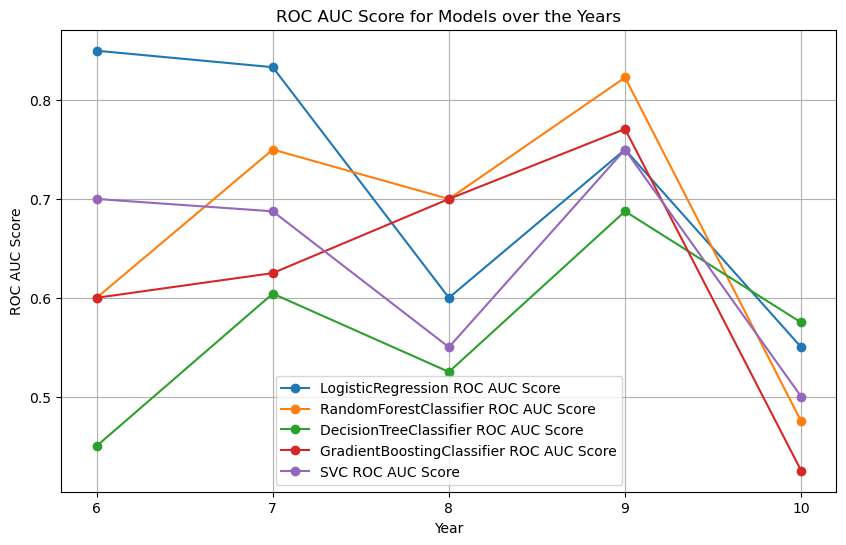

In [168]:
plt.figure(figsize=(10, 6))

# Plot the ROC AUC scores for all models
for model_name, roc_auc_list in roc_auc_scores.items():
    plt.plot(test_years, roc_auc_list, marker='o', label=f'{model_name} ROC AUC Score')
    mean = sum(roc_auc_list)/len(roc_auc_list)
    print(model_name,roc_auc_list)
    print("Mean: ", mean)
    standard_deviation = np.std(roc_auc_list)
    print("Standard Deviation:", standard_deviation)
    
plt.title('ROC AUC Score for Models over the Years')
plt.xlabel('Year')
plt.ylabel('ROC AUC Score')
plt.xticks(test_years)
plt.legend()
plt.grid(True)
plt.show()

LogisticRegression [0.7058823529411765, 0.823529411764706, 0.625, 0.823529411764706, 0.625]
Mean:  0.7205882352941176
Standard Deviation: 0.08908900724035862
RandomForestClassifier [0.6666666666666666, 0.75, 0.6666666666666666, 0.8, 0.5882352941176471]
Mean:  0.694313725490196
Standard Deviation: 0.07355528956395571
DecisionTreeClassifier [0.5333333333333333, 0.7368421052631579, 0.36363636363636365, 0.7777777777777777, 0.7058823529411765]
Mean:  0.6234943865903618
Standard Deviation: 0.1543334407975257
GradientBoostingClassifier [0.5714285714285715, 0.7777777777777777, 0.5714285714285715, 0.7777777777777777, 0.5882352941176471]
Mean:  0.6573295985060692
Standard Deviation: 0.0985368190927606
SVC [0.7999999999999999, 0.7777777777777777, 0.7058823529411765, 0.7272727272727273, 0.6666666666666665]
Mean:  0.7355199049316696
Standard Deviation: 0.048229823396739445


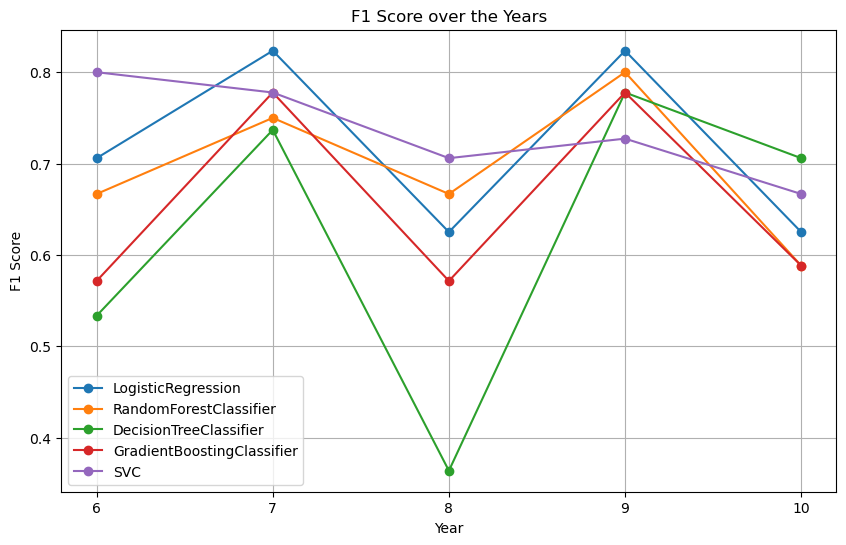

In [169]:
plt.figure(figsize=(10, 6))  # Define the size of the graph

for model_name, f1_list in f1_scores.items():
    plt.plot(test_years, f1_list, marker='o', label=model_name)
    mean = sum(f1_list)/len(f1_list)
    print(model_name,f1_list)
    print("Mean: ", mean)
    standard_deviation = np.std(f1_list)
    print("Standard Deviation:", standard_deviation)
    
plt.title('F1 Score over the Years')
plt.xlabel('Year')
plt.ylabel('F1 Score')
plt.xticks(test_years)
plt.legend()
plt.grid(True)
plt.show()

## Principal Component Analysis

Min Year: 1
Max Year: 10
Training Years: 1  to  5
Testing Year: 6

Training Years: 2  to  6
Testing Year: 7

Training Years: 3  to  7
Testing Year: 8

Training Years: 4  to  8
Testing Year: 9

Training Years: 5  to  9
Testing Year: 10



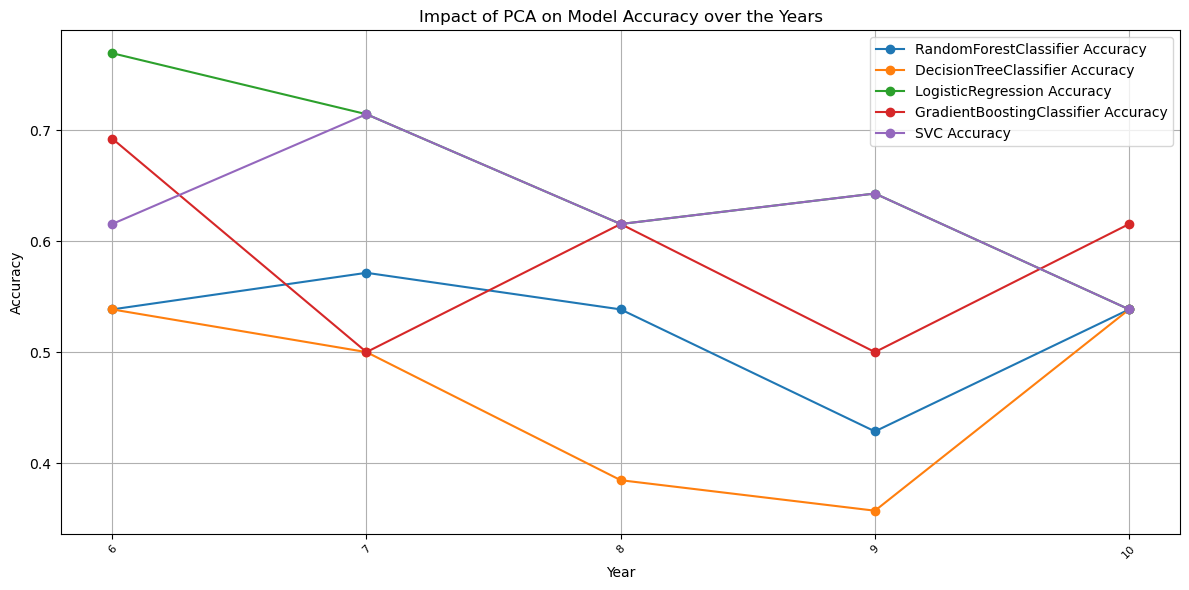

In [170]:

window_size = 5 
target_column = 'playoff'
#teams = pd.get_dummies(teams, columns=['tmID']) 

n_components = 2  
models = [RandomForestClassifier(n_estimators=200), 
          DecisionTreeClassifier(), 
          LogisticRegression(),
          GradientBoostingClassifier(n_estimators=100),
          SVC()]
accuracies = {model.__class__.__name__: [] for model in models}

splits,test_years = sliding_window_split(new_df, window_size, target_column, n_components)
    
for X_train, X_test, y_train, y_test in splits:
    for model in models:
        model_name = model.__class__.__name__
        model.fit(X_train, y_train)
        accuracy = model.score(X_test, y_test)
        accuracies[model_name].append(accuracy)


plt.figure(figsize=(12, 6))

for model_name, accuracy_list in accuracies.items():
    formatted_years = [f"{year}" for year in test_years]
    plt.plot(formatted_years, accuracy_list, marker='o', label=f'{model_name} Accuracy')

plt.title('Impact of PCA on Model Accuracy over the Years')
plt.xlabel('Year')
plt.ylabel('Accuracy')
plt.xticks(rotation=45, fontsize=8)  
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()


## Hyperparameter Tuning with GridSearch



In [171]:
import sklearn.metrics as metrics
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

In [172]:

# best interval for training
end_year = 5
start_year = 2

# Fill missing values in specified columns with 0
new_df.loc[:, columns_with_missing_values] = new_df[columns_with_missing_values].fillna(0)
train_mask = (new_df['year'] >= start_year) & (new_df['year'] <= end_year)
X_train = new_df[train_mask].drop([target_column], axis=1)
y_train = new_df[train_mask][target_column]
print("Training Years:", start_year ," to ", end_year)  

test_mask = new_df['year'] == end_year + 1
X_test = new_df[test_mask].drop([target_column], axis=1)
y_test = new_df[test_mask][target_column]



Training Years: 2  to  5


In [173]:

def grid_search(model, parameter_grid):

    grid_search = GridSearchCV(model,
                               param_grid=parameter_grid,
                               scoring='roc_auc', # Use ROC AUC score to evaluate models
                               cv=5,            # Use 5-fold cross-validation
                               verbose=2,       # Verbose output level 2 for more detailed output
                               n_jobs=-1,       # Use all processors in parallel
                               refit=True)      # Fit the best model on the whole dataset

    grid_search.fit(X_train, y_train)

    print(f"\nBest score: {grid_search.best_score_}")
    print(f"Best parameters: {grid_search.best_params_}")
    print(f"Best estimator: {grid_search.best_estimator_}")
    
    best_model = grid_search.best_estimator_
    best_model = grid_search.best_estimator_

    # Make predictions with the best model on test data
    best_model_pred = best_model.predict(X_test)

    # Compute the predicted probabilities for the positive class
    best_model_pred_proba = best_model.predict_proba(X_test)[:, -1]
    
    # Metrics
    print("\nAUC Score: ", metrics.roc_auc_score(y_test, best_model_pred_proba))
    print(f"Confusion matrix:\n{metrics.confusion_matrix(y_test, best_model_pred)}\n")
    print(f"Classification report:\n{metrics.classification_report(y_test, best_model_pred)}\n")

    # Plot the ROC curve for the best model
    metrics.plot_roc_curve(best_model, X_test, y_test, pos_label=0)
    plt.show
    
    return best_model,best_model_pred

In [174]:
scaler = StandardScaler()

# Fit the scaler to the training data (compute mean and standard deviation for scaling)
scaler.fit(X_train)

# Transform the training data by centering and scaling
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

Fitting 5 folds for each of 32 candidates, totalling 160 fits



Best score: 0.5460317460317461
Best parameters: {'C': 1, 'gamma': 'auto', 'kernel': 'sigmoid'}
Best estimator: SVC(C=1, gamma='auto', kernel='sigmoid', probability=True)

AUC Score:  0.725
Confusion matrix:
[[4 1]
 [4 4]]

Classification report:
              precision    recall  f1-score   support

         0.0       0.50      0.80      0.62         5
         1.0       0.80      0.50      0.62         8

    accuracy                           0.62        13
   macro avg       0.65      0.65      0.62        13
weighted avg       0.68      0.62      0.62        13




c:\Users\Utilizador\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:87: FutureWarning: Function plot_roc_curve is deprecated; Function :func:`plot_roc_curve` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: :meth:`sklearn.metric.RocCurveDisplay.from_predictions` or :meth:`sklearn.metric.RocCurveDisplay.from_estimator`.
  warnings.warn(msg, category=FutureWarning)


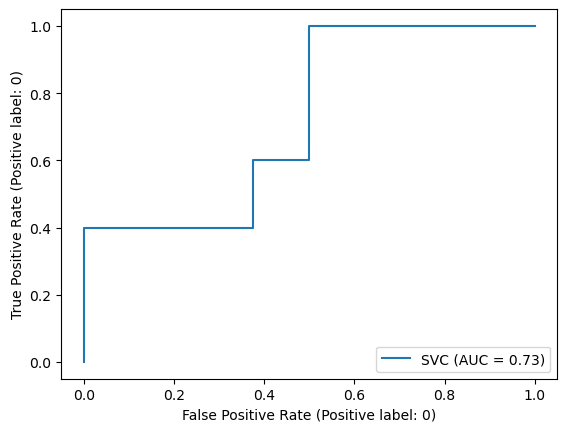

In [175]:
model = SVC(probability=True)
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'gamma': ['scale', 'auto']
}
svm,pred = grid_search(model, param_grid)


Fitting 5 folds for each of 60 candidates, totalling 300 fits

Best score: 0.5241269841269841
Best parameters: {'C': 0.001, 'max_iter': 100, 'penalty': 'l2', 'solver': 'liblinear'}
Best estimator: LogisticRegression(C=0.001, random_state=0, solver='liblinear')

AUC Score:  0.8
Confusion matrix:
[[4 1]
 [2 6]]

Classification report:
              precision    recall  f1-score   support

         0.0       0.67      0.80      0.73         5
         1.0       0.86      0.75      0.80         8

    accuracy                           0.77        13
   macro avg       0.76      0.78      0.76        13
weighted avg       0.78      0.77      0.77        13




c:\Users\Utilizador\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:87: FutureWarning: Function plot_roc_curve is deprecated; Function :func:`plot_roc_curve` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: :meth:`sklearn.metric.RocCurveDisplay.from_predictions` or :meth:`sklearn.metric.RocCurveDisplay.from_estimator`.
  warnings.warn(msg, category=FutureWarning)


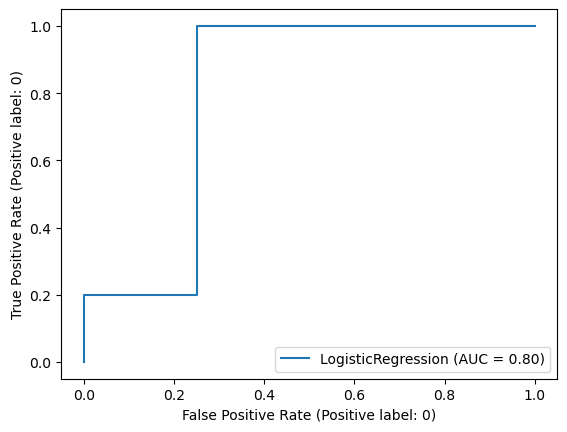

In [176]:
model = LogisticRegression(C=0.001, random_state=0, solver='liblinear')

parameter_grid = {'penalty': ['l1', 'l2'],  # Regularization type (L1 or L2)
    'C': [0.001, 0.01, 0.1, 1.0, 10.0],  # Inverse of regularization strength
    'solver': ['liblinear', 'saga'],  # Solver algorithm
    'max_iter': [100, 200, 300] } # Maximum number of iterations

ada,pred = grid_search(model, parameter_grid)

Fitting 5 folds for each of 144 candidates, totalling 720 fits

Best score: 0.5503174603174603
Best parameters: {'criterion': 'gini', 'max_features': None, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}
Best estimator: RandomForestClassifier(max_features=None, min_samples_leaf=4,
                       min_samples_split=10, random_state=0)

AUC Score:  0.7250000000000001
Confusion matrix:
[[2 3]
 [2 6]]

Classification report:
              precision    recall  f1-score   support

         0.0       0.50      0.40      0.44         5
         1.0       0.67      0.75      0.71         8

    accuracy                           0.62        13
   macro avg       0.58      0.57      0.58        13
weighted avg       0.60      0.62      0.61        13




c:\Users\Utilizador\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:87: FutureWarning: Function plot_roc_curve is deprecated; Function :func:`plot_roc_curve` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: :meth:`sklearn.metric.RocCurveDisplay.from_predictions` or :meth:`sklearn.metric.RocCurveDisplay.from_estimator`.
  warnings.warn(msg, category=FutureWarning)


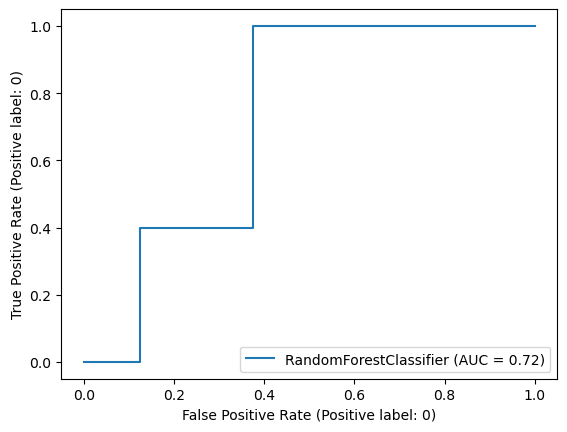

In [177]:
model = RandomForestClassifier(random_state=0)

parameter_grid = {'n_estimators': [100, 150, 200, 250],
                  'criterion': ['gini', 'entropy'],
                  'min_samples_split': [2, 5, 10],
                  'min_samples_leaf': [1, 2, 4],
                  'max_features': ['auto', None]}

rf,pred = grid_search(model, parameter_grid)

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Best score: 0.5717460317460317
Best parameters: {'algorithm': 'ball_tree', 'n_neighbors': 10, 'weights': 'uniform'}
Best estimator: KNeighborsClassifier(algorithm='ball_tree', n_neighbors=10)

AUC Score:  0.7625
Confusion matrix:
[[4 1]
 [4 4]]

Classification report:
              precision    recall  f1-score   support

         0.0       0.50      0.80      0.62         5
         1.0       0.80      0.50      0.62         8

    accuracy                           0.62        13
   macro avg       0.65      0.65      0.62        13
weighted avg       0.68      0.62      0.62        13




c:\Users\Utilizador\anaconda3\lib\site-packages\sklearn\neighbors\_classification.py:228: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
c:\Users\Utilizador\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:87: FutureWarning: Function plot_roc_curve is deprecated; Function :func:`plot_roc_curve` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: :meth:`sklearn.metric.RocCurveDisplay.from_predictions` or :meth:`sklearn.metric.RocCurveDisplay.from_estimator`.
  warnings.warn(msg, category=FutureWarning)


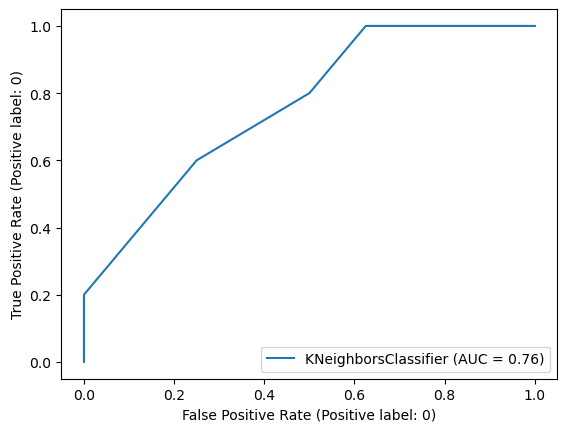

In [178]:
model = KNeighborsClassifier()

parameter_grid = {'n_neighbors': [5, 10, 15],
                  'weights': ['uniform', 'distance'],
                  'algorithm': ['ball_tree', 'kd_tree', 'brute']}

knn,pred = grid_search(model, parameter_grid)

Fitting 5 folds for each of 432 candidates, totalling 2160 fits

Best score: 0.4593650793650793
Best parameters: {'criterion': 'squared_error', 'learning_rate': 1.0, 'max_features': 'auto', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best estimator: GradientBoostingClassifier(criterion='squared_error', learning_rate=1.0,
                           max_features='auto', min_samples_leaf=2,
                           random_state=0)

AUC Score:  0.525
Confusion matrix:
[[2 3]
 [3 5]]

Classification report:
              precision    recall  f1-score   support

         0.0       0.40      0.40      0.40         5
         1.0       0.62      0.62      0.62         8

    accuracy                           0.54        13
   macro avg       0.51      0.51      0.51        13
weighted avg       0.54      0.54      0.54        13




c:\Users\Utilizador\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:87: FutureWarning: Function plot_roc_curve is deprecated; Function :func:`plot_roc_curve` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: :meth:`sklearn.metric.RocCurveDisplay.from_predictions` or :meth:`sklearn.metric.RocCurveDisplay.from_estimator`.
  warnings.warn(msg, category=FutureWarning)


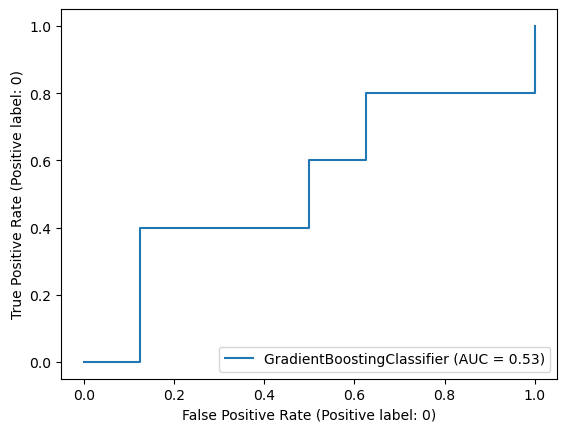

In [179]:
model = GradientBoostingClassifier(random_state=0)

parameter_grid = {'n_estimators': [50, 100, 150],
                  'learning_rate': [0.2, 0.3, 0.5, 1.0],
                  'criterion': ['friedman_mse', 'squared_error'],
                  'min_samples_split': [2, 5, 10],
                  'min_samples_leaf': [1, 2, 4],
                  'max_features': ['auto', None]}

gb,pred = grid_search(model, parameter_grid)


Fitting 5 folds for each of 25 candidates, totalling 125 fits



Best score: 0.5698412698412698
Best parameters: {'alpha': 0.1, 'hidden_layer_sizes': 10}
Best estimator: MLPClassifier(alpha=0.1, hidden_layer_sizes=10, random_state=0)

AUC Score:  0.675
Confusion matrix:
[[3 2]
 [2 6]]

Classification report:
              precision    recall  f1-score   support

         0.0       0.60      0.60      0.60         5
         1.0       0.75      0.75      0.75         8

    accuracy                           0.69        13
   macro avg       0.68      0.68      0.68        13
weighted avg       0.69      0.69      0.69        13




c:\Users\Utilizador\anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:692: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Utilizador\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:87: FutureWarning: Function plot_roc_curve is deprecated; Function :func:`plot_roc_curve` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: :meth:`sklearn.metric.RocCurveDisplay.from_predictions` or :meth:`sklearn.metric.RocCurveDisplay.from_estimator`.
  warnings.warn(msg, category=FutureWarning)


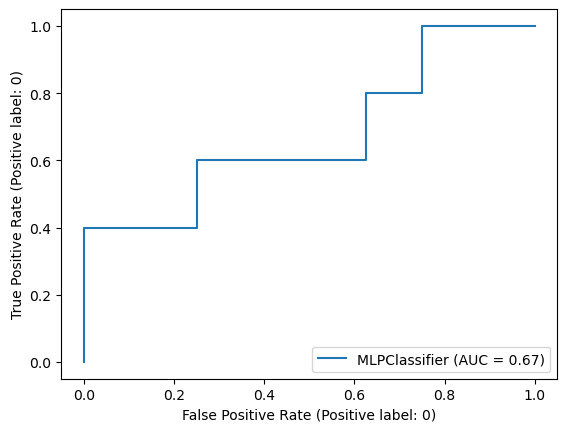

In [180]:
model = MLPClassifier(alpha=1, hidden_layer_sizes=150, random_state=0)

parameter_grid = {'alpha': [0.1, 0.25, 0.5, 0.75, 0.85],
                    'hidden_layer_sizes': [10, 20, 30, 60, 100],
                    
                    }

mlp,pred = grid_search(model, parameter_grid)

# Kaggle submission to predict year 11


### SVC

In [181]:
window_size = 5
year = 11
model = SVC()
new_df_train = new_df[(new_df['year'] <= year - 1) & (new_df['year'] >= year - window_size)] 
new_df_test = new_df[new_df['year'] == year]

X_train = new_df_train.drop(['playoff'], axis=1)
y_train = new_df_train['playoff']

X_test = new_df_test.drop(['playoff'], axis=1)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(y_pred)


[0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Decision Tree

In [182]:

window_size = 5
year = 11
model = DecisionTreeClassifier()
new_df_train = new_df[(new_df['year'] <= year - 1) & (new_df['year'] >= year - window_size)] #intervalo
new_df_test = new_df[new_df['year'] == year]

X_train = new_df_train.drop(['playoff'], axis=1)
y_train = new_df_train['playoff']

X_test = new_df_test.drop(['playoff'], axis=1)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(y_pred)

[0. 0. 1. 1. 0. 0. 0. 0. 0. 1. 0. 1.]


### Random Forest

In [183]:
window_size = 5
year = 11
model = RandomForestClassifier(n_estimators=200)
new_df_train = new_df[(new_df['year'] <= year - 1) & (new_df['year'] >= year - window_size)] #
new_df_test = new_df[new_df['year'] == year]

X_train = new_df_train.drop(['playoff'], axis=1)
y_train = new_df_train['playoff']

X_test = new_df_test.drop(['playoff'], axis=1)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(y_pred)

[0. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0.]


### Logistic Regression

In [188]:
window_size = 5
year = 11
model = LogisticRegression()
new_df_train = new_df[(new_df['year'] <= year - 1) & (new_df['year'] >= year - window_size)] 
new_df_test = new_df[new_df['year'] == year]

X_train = new_df_train.drop(['playoff'], axis=1)
y_train = new_df_train['playoff']

X_test = new_df_test.drop(['playoff'], axis=1)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(y_pred)


[1. 0. 0. 1. 1. 0. 1. 1. 1. 1. 0. 1.]


### Gradient Boosting 

In [185]:
window_size = 5
year = 11
model = GradientBoostingClassifier(n_estimators=100)
new_df_train = new_df[(new_df['year'] <= year - 1) & (new_df['year'] >= year - window_size)] #
new_df_test = new_df[new_df['year'] == year]

X_train = new_df_train.drop(['playoff'], axis=1)
y_train = new_df_train['playoff']

X_test = new_df_test.drop(['playoff'], axis=1)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(y_pred)


[1. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0.]


In [189]:
# Displaying our table with the best model predictions
results_year_11 = X_test.copy()
results_year_11['y_pred'] = y_pred 

results_year_11['tmID'] = encoder.inverse_transform(results_year_11['tmID'])
results_year_11 = results_year_11.groupby(['tmID']).agg({'y_pred': 'median'}).reset_index()
results_year_11.tail(20)


,tmID,y_pred
0,ATL,1.0
1,CHI,0.0
2,CON,0.0
3,IND,1.0
4,LAS,1.0
5,MIN,0.0
6,NYL,1.0
7,PHO,1.0
8,SAS,1.0
9,SEA,1.0


In [187]:
# Create a dictionary mapping the original class labels to their encoded values
class_mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
print("Class - Label Mapping:")

# see the number encoded for each team
for class_label, encoded_value in class_mapping.items():
    print(f"{class_label}: {encoded_value}")

Class - Label Mapping:
ATL: 0
CHA: 1
CHI: 2
CLE: 3
CON: 4
DET: 5
HOU: 6
IND: 7
LAS: 8
MIA: 9
MIN: 10
NYL: 11
ORL: 12
PHO: 13
POR: 14
SAC: 15
SAS: 16
SEA: 17
TUL: 18
UTA: 19
WAS: 20
